# **Customer LifeTime Value Analysis -- Olist E-Commerce**
## AI for Communication and Marketing - Lab Exam Part 3
### Academic Year 2025/2026 | B.Sc. in Artificial Intelligence

---

**Student:** Daria Miele  
**Matricola:** 535702 

---
### Business Context
Customer Lifetime Value — the total revenue a business can expect from a single 
customer over the course of their relationship — is the foundational metric for 
any data-driven marketing strategy. Without it, budget allocation across 
acquisition, retention, and win-back campaigns is necessarily arbitrary.

This project addresses the following business question: given historical 
transaction data from Olist's e-commerce marketplace, can we estimate how much 
revenue each existing customer will generate over the next 90 days — and identify 
which customers are worth investing in?

The dataset is the Brazilian E-Commerce Public Dataset by Olist, comprising 
over 99,000 orders across eight relational tables covering customers, orders, 
payments, and products. After cleaning and aggregation, the analytical base 
contains 96,417 delivered orders from 61,872 unique customers observed between 
January 2017 and August 2018.

Two modelling approaches are developed and compared: a probabilistic BTYD 
framework (BG/NBD + Gamma-Gamma), which estimates each customer's purchase 
probability and expected monetary value from their transaction history alone, 
and a supervised machine learning regressor (XGBoost and Random Forest), which 
learns the relationship between calibration-period features and holdout revenue. 
The deliverable is a ranked customer table combining predicted CLTV and alive 
probability, enabling the Marketing team to prioritise retention investment and 
target high-value win-back candidates before their window closes.

---
## **Setup & Imports**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Probabilistic CLTV models
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import calibration_and_holdout_data
from lifetimes.plotting import (
    plot_frequency_recency_matrix,
    plot_probability_alive_matrix,
    plot_period_transactions,
)

# Machine learning
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

RANDOM_STATE = 42
PALETTE     = "mako"
DPI         = 150
FIG_DIR     = "figures/"

import os
os.makedirs(FIG_DIR, exist_ok=True)

print("Python version:", __import__("sys").version)
print("pandas:", pd.__version__, "| numpy:", np.__version__)

Python version: 3.14.3 | packaged by conda-forge | (main, Feb  9 2026, 21:56:48) [MSC v.1944 64 bit (AMD64)]
pandas: 3.0.1 | numpy: 2.4.2


#### Dataset Loading

The Olist dataset is distributed across eight relational tables. For CLTV analysis, three are essential: `orders` (timestamps and status), `order_payments` (transaction values), and `customers` (unique customer identity). The remaining tables will be loaded for completeness but are not primary inputs to the modeling pipeline.

In [3]:
DATA_DIR = "../data/"

orders    = pd.read_csv(DATA_DIR + "olist_orders_dataset.csv",
                        parse_dates=["order_purchase_timestamp",
                                     "order_approved_at",
                                     "order_delivered_customer_date",
                                     "order_estimated_delivery_date"])

payments  = pd.read_csv(DATA_DIR + "olist_order_payments_dataset.csv")
items     = pd.read_csv(DATA_DIR + "olist_order_items_dataset.csv")
customers = pd.read_csv(DATA_DIR + "olist_customers_dataset.csv")
products  = pd.read_csv(DATA_DIR + "olist_products_dataset.csv")
sellers   = pd.read_csv(DATA_DIR + "olist_sellers_dataset.csv")
reviews   = pd.read_csv(DATA_DIR + "olist_order_reviews_dataset.csv")
geo       = pd.read_csv(DATA_DIR + "olist_geolocation_dataset.csv")
cat_trans = pd.read_csv(DATA_DIR + "product_category_name_translation.csv")

tables = {
    "orders": orders, "payments": payments, "items": items,
    "customers": customers, "products": products, "sellers": sellers,
    "reviews": reviews, "geo": geo
}

summary = pd.DataFrame({
    "rows":    {k: v.shape[0] for k, v in tables.items()},
    "columns": {k: v.shape[1] for k, v in tables.items()},
}).astype(int)

summary.style.background_gradient(cmap="mako", axis=0)

,rows,columns
orders,99441,8
payments,103886,5
items,112650,7
customers,99441,5
products,32951,9
sellers,3095,4
reviews,99224,7
geo,1000163,5


The dataset comprises 99,441 orders distributed across eight relational tables. Orders and customers share an identical row count, 
confirming a one-to-one mapping between `order_id` and `customer_id`. The 
payments table contains 103,886 rows against 99,441 orders, evidence of split 
or installment payments that the aggregation step has already collapsed.

#### Relational Join — Master Transaction Table

CLTV analysis requires a single flat table at the **order level**: one row per order, with the purchase timestamp, the customer's unique identifier, and the total payment value. Three design choices are made here and will be revisited in the cleaning section:

- `customer_unique_id` is used instead of `customer_id`, because the latter is order-scoped in this dataset — the same physical customer receives a different `customer_id` for each order, making repeat purchases invisible without the unique key.
- Payment value is aggregated by summing across all `payment_sequential` rows for the same order (split payments, installments).
- The join is left-anchored on orders, so the shape of the master table equals the number of orders.

In [6]:
# Aggregate payments to order level
payments_agg = (
    payments
    .groupby("order_id", as_index=False)
    .agg(total_payment=("payment_value", "sum"),
         payment_types=("payment_type", "nunique"))
)

# Aggregate items to order level
items_agg = (
    items
    .groupby("order_id", as_index=False)
    .agg(n_items=("order_item_id", "count"),
         total_item_value=("price", "sum"),
         total_freight=("freight_value", "sum"))
)

# Bring in unique customer identity
orders_cust = orders.merge(
    customers[["customer_id", "customer_unique_id", "customer_state"]],
    on="customer_id", how="left"
)

# Join payments and items
master = (
    orders_cust
    .merge(payments_agg, on="order_id", how="left")
    .merge(items_agg,    on="order_id", how="left")
)

print(f"Master table shape: {master.shape}")
print(f"Unique orders:             {master['order_id'].nunique():,}")
print(f"Unique customer_id:        {master['customer_id'].nunique():,}")
print(f"Unique customer_unique_id: {master['customer_unique_id'].nunique():,}")
master.head()

Master table shape: (99441, 15)
Unique orders:             99,441
Unique customer_id:        99,441
Unique customer_unique_id: 96,096


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_state,total_payment,payment_types,n_items,total_item_value,total_freight
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,SP,38.7100,2.0000,1.0000,29.9900,8.7200
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,BA,141.4600,1.0000,1.0000,118.7000,22.7600
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,GO,179.1200,1.0000,1.0000,159.9000,19.2200
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,RN,72.2000,1.0000,1.0000,45.0000,27.2000
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,SP,28.6200,1.0000,1.0000,19.9000,8.7200


The master table joins cleanly to 99,441 rows across 15 columns — no orders 
are lost in any of the three merges. The gap between `customer_id` (99,441) 
and `customer_unique_id` (96,096) confirms that approximately 3,300 physical 
customers placed more than one order under different session-scoped IDs, making 
the unique key essential for repeat-purchase analysis.

Each order now carries four value dimensions: `total_payment` (what the customer 
actually paid, including installments and vouchers), `total_item_value` (sum of 
product prices), `total_freight` (shipping costs), and `n_items` (basket size). 
The systematic gap between `total_payment` and the sum of item value plus freight 
visible in the sample rows — e.g. row 0: 38.71 paid vs 29.99 + 8.72 = 38.71 — 
confirms the join is arithmetically consistent for single-payment orders.

---
## **Data Audit & Cleaning**

### 1.1 Missing Value Audit 
Before any cleaning decision is made, the extent and distribution of missing 
values across the master table is mapped column by column.

In [7]:
missing = pd.DataFrame({
    "missing_count": master.isnull().sum(),
    "missing_pct":   master.isnull().sum() / len(master) * 100
}).query("missing_count > 0").sort_values("missing_pct", ascending=False)

missing.style.background_gradient(cmap="mako", subset=["missing_pct"]).format({
    "missing_count": "{:,.0f}",
    "missing_pct":   "{:.2f}%"
})

,missing_count,missing_pct
order_delivered_customer_date,"2,965",2.98%
order_delivered_carrier_date,"1,783",1.79%
total_item_value,775,0.78%
n_items,775,0.78%
total_freight,775,0.78%
order_approved_at,160,0.16%
total_payment,1,0.00%
payment_types,1,0.00%


Eight columns carry missing values, falling into three distinct groups by cause.

- The delivery date columns (`order_delivered_customer_date` at 2.98% and 
`order_delivered_carrier_date` at 1.79%) are structurally missing: orders that 
were cancelled, unavailable, or still in transit at snapshot time never receive 
a delivery timestamp. These nulls are 
informative and will be addressed in the order status filtering step.

- The items-side columns (`total_item_value`, `n_items`, `total_freight`) share 
an identical count of 775 missing rows (0.78%), confirming that these are orders 
present in the orders table but absent from the items table — likely cancelled 
orders for which no item record was ever created.

- `order_approved_at` (160 rows) and the single missing 
row each for `total_payment` and `payment_types` are negligible in volume and 
will be dropped during the cleaning pipeline.

#### 1.2 Duplicate Detection

Duplicate records are checked at three levels: order ID, customer–order 
combinations, and customer unique ID within the same purchase date, which would 
indicate data entry errors rather than genuine repeat purchases.

In [8]:
dup_orders    = master.duplicated(subset="order_id").sum()
dup_cust_date = master.duplicated(
    subset=["customer_unique_id", "order_purchase_timestamp"]
).sum()
dup_payment   = payments.duplicated(
    subset=["order_id", "payment_sequential"]
).sum()

pd.DataFrame({
    "check": [
        "Duplicate order_id in master",
        "Duplicate customer × timestamp in master",
        "Duplicate order_id × payment_sequential in payments"
    ],
    "count": [dup_orders, dup_cust_date, dup_payment]
}).style.background_gradient(cmap="mako", subset=["count"])

,check,count
0,Duplicate order_id in master,0
1,Duplicate customer × timestamp in master,292
2,Duplicate order_id × payment_sequential in payments,0


No duplicate `order_id` records exist in the master table, and the payments 
table contains no repeated sequential entries — the join structure is clean.

The 292 cases where the same `customer_unique_id` shares an identical purchase 
timestamp are inspected to determine whether they represent data entry errors or 
legitimate platform behaviour.


In [21]:
dupes = master[
    master.duplicated(subset=["customer_unique_id", "order_purchase_timestamp"], keep=False)
].sort_values(["customer_unique_id", "order_purchase_timestamp"])

print(f"Affected customers: {dupes['customer_unique_id'].nunique()}")
print(f"Affected orders:    {len(dupes)}")

dupes[["customer_unique_id", "order_id", "order_purchase_timestamp",
       "total_payment", "n_items"]].head(10)

Affected customers: 290
Affected orders:    582


,customer_unique_id,order_id,order_purchase_timestamp,total_payment,n_items
55044,02b20b7c813efede140142ac610e36dc,25ce3a22fa2537206c22c8bef4f9b593,2018-03-19 20:50:39,101.7400,1.0000
57156,02b20b7c813efede140142ac610e36dc,62ec63f37c8ed14ce3dba43a02721f5e,2018-03-19 20:50:39,92.8300,1.0000
4167,031e19fc630c4121f1238716f41675c3,246b14cc444e8a7df0afd80495dfa052,2018-07-04 01:20:01,17.9700,1.0000
51086,031e19fc630c4121f1238716f41675c3,f707ff2a9514dce20b267136b60af042,2018-07-04 01:20:01,17.9700,1.0000
11035,050555c26479bbb8ba0740c37e7454d0,f014aa85d8f495d824d120e9035faacb,2018-04-07 12:07:04,49.4400,1.0000
19653,050555c26479bbb8ba0740c37e7454d0,4f173306347cca2ee2a05590d617854a,2018-04-07 12:07:04,49.4400,1.0000
22179,06a52782a04f0086d16b9c22d0e29438,56ae029ed8bd31758f66831a64bf5629,2017-05-06 20:11:10,51.1100,1.0000
58749,06a52782a04f0086d16b9c22d0e29438,d9e44c3fd2ce16086619f299e92e12d8,2017-05-06 20:11:10,51.1100,1.0000
45004,0710e0c85fe7cb494d624e0863782e46,f474a46ca16058fe246cdabe215c66da,2018-03-21 15:06:40,189.6800,1.0000
56813,0710e0c85fe7cb494d624e0863782e46,baed56f3eda9223b74c6cf175f05678e,2018-03-21 15:06:40,49.5600,1.0000


The 582 flagged records involve 290 customers, each appearing exactly twice 
with an identical purchase timestamp. Two distinct patterns emerge: pairs where 
both the timestamp and payment value are identical (technical duplicates, likely 
caused by a double-submission at the platform level), and pairs where the 
timestamp matches but payment values differ (legitimate split orders, where a 
single customer session generates two separate order records for items fulfilled 
by different sellers).

Technical duplicates are removed by keeping only the first occurrence within 
each customer–timestamp–payment group. Split orders are retained as distinct 
transactions, since they represent real revenue events and will naturally 
collapse at the customer level during RFM aggregation.

In [22]:
master_deduped = master.drop_duplicates(
    subset=["customer_unique_id", "order_purchase_timestamp", "total_payment"],
    keep="first"
)

removed = len(master) - len(master_deduped)
print(f"Technical duplicates removed: {removed}")
print(f"Rows remaining: {len(master_deduped):,}")

master = master_deduped.copy()

Technical duplicates removed: 41
Rows remaining: 99,400


41 technical duplicates are removed — exactly the pairs where both timestamp 
and payment value were identical. The remaining 541 flagged records 
are retained as legitimate split orders. 

#### 1.3 Order Status Filtering

The dataset contains orders in multiple lifecycle states. Only orders that 
represent completed, revenue-generating transactions are valid inputs for CLTV 
modelling. The distribution of order statuses is inspected before deciding which 
to retain.

In [9]:
status_counts = (
    master["order_status"]
    .value_counts()
    .reset_index()
    .rename(columns={"order_status": "status", "count": "n_orders"})
)
status_counts["pct"] = status_counts["n_orders"] / len(master) * 100

status_counts.style.background_gradient(cmap="mako", subset=["n_orders"]).format({
    "n_orders": "{:,.0f}",
    "pct": "{:.2f}%"
})

,status,n_orders,pct
0,delivered,"96,478",97.02%
1,shipped,"1,107",1.11%
2,canceled,625,0.63%
3,unavailable,609,0.61%
4,invoiced,314,0.32%
5,processing,301,0.30%
6,created,5,0.01%
7,approved,2,0.00%


97.02% of orders carry a `delivered` status, confirming that the dataset is 
dominated by completed transactions. The remaining 2.98% spans seven non-final 
states: `shipped` (1.11%) represents orders in transit at snapshot time — 
revenue is not yet confirmed; `canceled` (0.63%) and `unavailable` (0.61%) 
represent failed transactions that generated no real revenue; `invoiced`, 
`processing`, `created`, and `approved` are intermediate pipeline states where 
fulfilment is incomplete.

For CLTV modelling, only `delivered` orders are retained. All other statuses 
are removed: they do not represent confirmed customer spend and would introduce 
noise into both the probabilistic and ML models.

#### 1.4 Outlier Analysis & Capping

Before applying the status filter and finalising the clean dataset, the 
distribution of order values is inspected for extreme observations. Outliers 
in `total_payment` can distort both the Gamma-Gamma model's monetary value 
estimates and the ML regression target.

In [10]:
# Restrict to delivered orders for outlier inspection
delivered = master[master["order_status"] == "delivered"].copy()

value_stats = delivered["total_payment"].describe(
    percentiles=[.25, .50, .75, .90, .95, .99]
).to_frame().T

value_stats.style.background_gradient(cmap="mako", axis=1).format("{:.2f}")

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
total_payment,96477.00,159.86,218.81,9.59,61.88,105.28,176.33,305.97,446.31,1052.39,13664.08


The distribution of `total_payment` is strongly right-skewed. The median order 
value is 105.28 BRL while the mean sits at 159.86 BRL — a gap of over 50 BRL 
driven entirely by the upper tail. The 99th percentile reaches 1,052 BRL, and 
the maximum is 13,664 BRL, more than 13 times the 99th percentile value. The 
standard deviation of 218.81 exceeds the mean, confirming high dispersion.


#### 1.5 Date Integrity Checks

Purchase timestamps are the backbone of CLTV analysis — recency, frequency, 
and customer tenure all derive from them. Two checks are run: the overall 
date range of the dataset, and the detection of any orders where the purchase 
timestamp is logically inconsistent (approved before purchase or 
delivered before shipped).

In [17]:
date_range = pd.DataFrame({
    "min": [delivered["order_purchase_timestamp"].min()],
    "max": [delivered["order_purchase_timestamp"].max()],
    "n_days": [(delivered["order_purchase_timestamp"].max() - delivered["order_purchase_timestamp"].min()).days]
}, index=["order_purchase_timestamp"])

approved_before_purchase = (delivered["order_approved_at"] < delivered["order_purchase_timestamp"]).sum()

delivered_before_shipped = (delivered["order_delivered_customer_date"] < delivered["order_delivered_carrier_date"]).sum()

inconsistencies = pd.DataFrame({
    "check": ["Approved before purchase", "Delivered to customer before carrier pickup"],
    "count": [approved_before_purchase, delivered_before_shipped]
})

display(date_range)
display(inconsistencies.style.background_gradient(cmap="mako", subset=["count"]))

,min,max,n_days
order_purchase_timestamp,2016-09-15 12:16:38,2018-08-29 15:00:37,713


,check,count
0,Approved before purchase,0
1,Delivered to customer before carrier pickup,23


The delivered orders span 713 days, from September 2016 to August 2018. 

No orders show an approval timestamp preceding the purchase timestamp, 
confirming that the core event sequence is logically consistent. The 23 cases 
where the customer delivery date precedes the carrier pickup date are likely 
timestamp recording errors at the logistics level. These records represent 
0.02% of delivered orders and will be dropped during the cleaning pipeline.

#### 1.6 Cleaning Pipeline

All decisions identified in sections 1.1 through 1.5 are applied in a single 
sequential pipeline. Each step is documented with the row count before and 
after, so the cumulative impact of every filter is explicit and traceable.

In [23]:
clean = master.copy()
log = []

def log_step(label, df):
    log.append({"step": label, "rows_remaining": len(df)})

log_step("0 — raw master (after dedup)", clean)

# Step 1: keep only delivered orders
clean = clean[clean["order_status"] == "delivered"]
log_step("1 — delivered only", clean)

# Step 2: drop rows with missing total_payment
clean = clean[clean["total_payment"].notna()]
log_step("2 — drop missing total_payment", clean)

# Step 3: drop rows with missing items-side columns
clean = clean[clean["total_item_value"].notna()]
log_step("3 — drop missing item values", clean)

# Step 4: drop rows with missing purchase timestamp
clean = clean[clean["order_purchase_timestamp"].notna()]
log_step("4 — drop missing purchase timestamp", clean)

# Step 5: drop logical date inconsistencies
clean = clean[
    ~(clean["order_delivered_customer_date"] < clean["order_delivered_carrier_date"])
]
log_step("5 — drop delivery date inconsistencies", clean)

# Step 6: cap total_payment at 99th percentile
cap_value = clean["total_payment"].quantile(0.99)
clean["total_payment"] = clean["total_payment"].clip(upper=cap_value)
log_step("6 — cap total_payment at 99th pct", clean)

# Step 7: drop zero-value orders
clean = clean[clean["total_payment"] > 0]
log_step("7 — drop zero-value orders", clean)

pipeline_log = pd.DataFrame(log)
pipeline_log["rows_dropped"] = pipeline_log["rows_remaining"].shift(1) - pipeline_log["rows_remaining"]
pipeline_log["rows_dropped"] = pipeline_log["rows_dropped"].fillna(0).astype(int)

pipeline_log.style.background_gradient(cmap="mako", subset=["rows_remaining"]).format({
    "rows_remaining": "{:,.0f}",
    "rows_dropped":   "{:,.0f}"
})

,step,rows_remaining,rows_dropped
0,0 — raw master (after dedup),"99,400",0
1,1 — delivered only,"96,441","2,959"
2,2 — drop missing total_payment,"96,440",1
3,3 — drop missing item values,"96,440",0
4,4 — drop missing purchase timestamp,"96,440",0
5,5 — drop delivery date inconsistencies,"96,417",23
6,6 — cap total_payment at 99th pct,"96,417",0
7,7 — drop zero-value orders,"96,417",0


The cleaning pipeline removes 2,983 records in total, retaining 96,417 orders 
— 97.0% of the deduplicated master table. The dominant filter is the status 
filter (step 1), which eliminates 2,959 non-delivered orders covering 
cancellations, unavailable items, and orders still in transit at snapshot time. 
The single missing payment record (step 2) and the 23 delivery date 
inconsistencies (step 5) account for the remainder. Steps 3, 4, and 7 produce 
no additional drops, confirming that all delivered orders carry complete item 
values, valid timestamps, and non-zero payment amounts. The 99th percentile cap 
(step 6) modifies values in-place without removing rows.

The clean dataset of 96,417 orders is the sole input to all subsequent 
analysis and modelling steps.

#### 1.7 Calibration / Holdout Split

The clean dataset spans September 2016 to August 2018 — 713 days. To train 
and validate the CLTV models, the timeline is divided into two non-overlapping 
periods. The monthly order volume is inspected first to identify a cut point 
that balances sufficient training history against a meaningful holdout window.

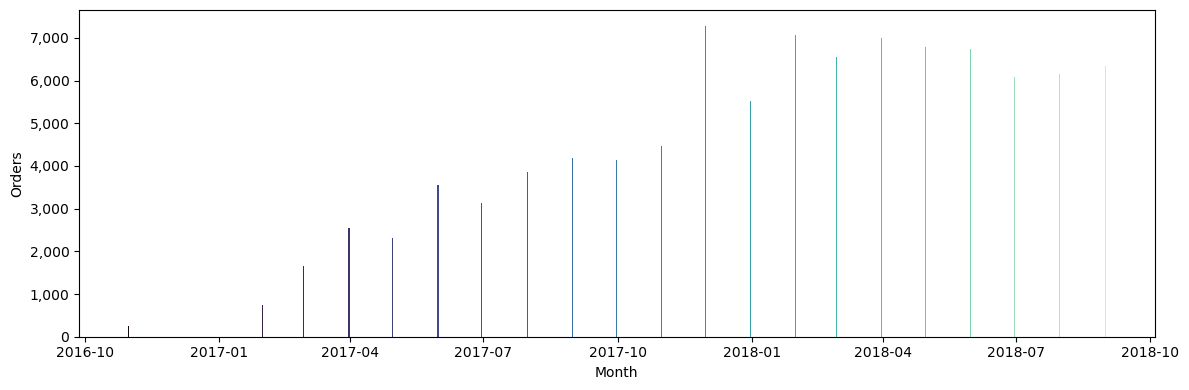

,month,n_orders
11,2017-09-30 00:00:00,"4,149"
12,2017-10-31 00:00:00,"4,478"
13,2017-11-30 00:00:00,"7,288"
14,2017-12-31 00:00:00,"5,513"
15,2018-01-31 00:00:00,"7,067"
16,2018-02-28 00:00:00,"6,553"
17,2018-03-31 00:00:00,"7,001"
18,2018-04-30 00:00:00,"6,793"
19,2018-05-31 00:00:00,"6,748"
20,2018-06-30 00:00:00,"6,092"


In [25]:
monthly = (
    clean
    .set_index("order_purchase_timestamp")
    .resample("ME")["order_id"]
    .count()
    .reset_index()
    .rename(columns={"order_purchase_timestamp": "month", "order_id": "n_orders"})
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(monthly["month"], monthly["n_orders"],
       color=sns.color_palette(PALETTE, len(monthly)))
ax.set_xlabel("Month")
ax.set_ylabel("Orders")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.savefig(FIG_DIR + "monthly_order_volume.png", dpi=DPI)
plt.show()

display(monthly.tail(12).style.background_gradient(cmap="mako", subset=["n_orders"])
        .format({"n_orders": "{:,.0f}"}))

Order volume grows steadily from the platform's launch in late 2016 through 
mid-2017, then stabilises at 6,000–7,000 orders per month from November 2017 
onwards. The November 2017 spike to 7,289 orders corresponds to Black Friday. 
The 2016 months are negligible in volume — fewer than 200 orders in October 
2016 — and represent the platform's ramp-up phase rather than steady-state 
behaviour.

The data is sufficiently dense from January 2017 onward to support a 
calibration period. The split is defined as follows:

- **Calibration period**: 1 January 2017 – 31 March 2018 (15 months)
- **Holdout period**: 1 April 2018 – 31 August 2018 (5 months)

This gives the probabilistic models 15 months of purchase history to estimate 
individual-level parameters, and a 5-month holdout window — close to the 
assignment's requested 90-day horizon — with stable, high-volume data on both 
sides of the cut. The sparse 2016 tail is excluded from both periods to avoid 
biasing frequency and recency estimates.

In [26]:
CAL_START  = pd.Timestamp("2017-01-01")
CAL_END    = pd.Timestamp("2018-03-31")
HOLD_END   = pd.Timestamp("2018-08-31")

clean = clean[clean["order_purchase_timestamp"] >= CAL_START].copy()

calibration = clean[clean["order_purchase_timestamp"] <= CAL_END].copy()
holdout     = clean[
    (clean["order_purchase_timestamp"] > CAL_END) &
    (clean["order_purchase_timestamp"] <= HOLD_END)
].copy()

split_summary = pd.DataFrame({
    "period":     ["calibration", "holdout"],
    "start":      [CAL_START, CAL_END + pd.Timedelta(days=1)],
    "end":        [CAL_END, HOLD_END],
    "n_orders":   [len(calibration), len(holdout)],
    "n_customers":[calibration["customer_unique_id"].nunique(),
                   holdout["customer_unique_id"].nunique()]
})

split_summary.style.background_gradient(cmap="mako", subset=["n_orders", "n_customers"]).format({
    "n_orders":    "{:,.0f}",
    "n_customers": "{:,.0f}"
})

,period,start,end,n_orders,n_customers
0,calibration,2017-01-01 00:00:00,2018-03-31 00:00:00,"63,859","61,872"
1,holdout,2018-04-01 00:00:00,2018-08-31 00:00:00,"32,296","31,822"


The calibration period contains 63,859 orders from 61,872 unique customers — 
the gap of roughly 2,000 confirms that a meaningful share of customers placed 
more than one order during the 15-month training window, which is exactly the 
repeat purchase signal the BG/NBD model requires. The holdout period contains 
32,296 orders from 31,822 unique customers across the following 5 months.

The two periods together cover 96,155 of the 96,417 clean orders; the 262 
orders falling outside the defined windows are intentionally excluded to avoid 
the sparse 2016 ramp-up period biasing frequency and recency estimates.

---
## **Exploratory Data Analysis**

### 2.1 Purchase Frequency Distribution

Purchase frequency is computed at the customer level over the calibration 
period — the number of distinct orders placed by each unique customer. 

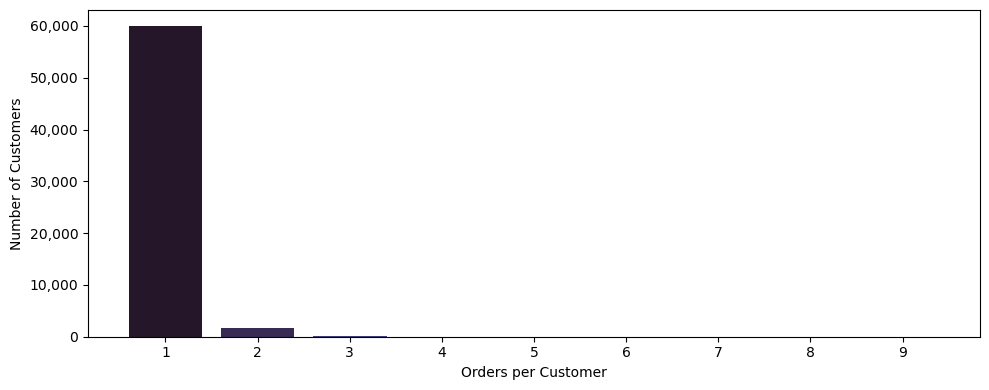

,orders_per_customer,n_customers,pct
0,1,"60,073",97.09%
1,2,"1,662",2.69%
2,3,110,0.18%
3,4,15,0.02%
4,5,6,0.01%
5,6,3,0.00%
6,7,1,0.00%
7,8,1,0.00%


In [27]:
freq = (
    calibration
    .groupby("customer_unique_id")["order_id"]
    .count()
    .reset_index()
    .rename(columns={"order_id": "n_orders"})
)

freq_dist = (
    freq["n_orders"]
    .value_counts()
    .sort_index()
    .reset_index()
    .rename(columns={"n_orders": "orders_per_customer", "count": "n_customers"})
)
freq_dist["pct"] = freq_dist["n_customers"] / freq_dist["n_customers"].sum() * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(freq_dist["orders_per_customer"], freq_dist["n_customers"],
       color=sns.color_palette(PALETTE, len(freq_dist)))
ax.set_xlabel("Orders per Customer")
ax.set_ylabel("Number of Customers")
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.tight_layout()
plt.savefig(FIG_DIR + "frequency_distribution.png", dpi=DPI)
plt.show()

freq_dist.head(8).style.background_gradient(cmap="mako", subset=["n_customers"]).format({
    "n_customers": "{:,.0f}",
    "pct": "{:.2f}%"
})

The frequency distribution reveals an extreme concentration of one-time buyers: 
97.09% of customers placed exactly one order during the calibration period. Only 
2.69% returned for a second purchase, and fewer than 0.20% placed three or more 
orders. The maximum observed frequency is 8 orders over 15 months.

This pattern is characteristic of non-contractual e-commerce marketplaces and 
is not a data quality issue — it reflects genuine customer behaviour. It does, 
however, have direct implications for CLTV modelling: the BG/NBD model must 
estimate future repeat purchases from a population where repeat purchase signals 
are sparse, making the calibration period length and the quality of the monetary 
value estimates especially critical.

### 2.2 Recency Distribution

Recency is defined as the number of days between a customer's last purchase and 
the end of the calibration period (31 March 2018). A customer who purchased 
recently has low recency; a customer who purchased early and never returned has 
high recency. The distribution is computed only for the calibration period.

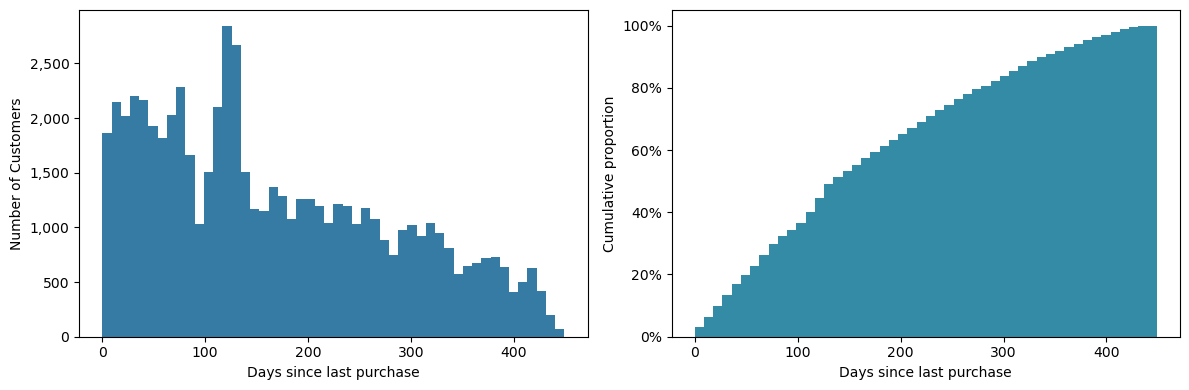

,count,mean,std,min,25%,50%,75%,90%,max
recency_days,61872.0,166.6,116.6,0.0,68.0,138.0,254.0,342.0,449.0


In [28]:
CAL_END_DT = pd.Timestamp("2018-03-31")

recency = (
    calibration
    .groupby("customer_unique_id")["order_purchase_timestamp"]
    .max()
    .reset_index()
    .rename(columns={"order_purchase_timestamp": "last_purchase"})
)
recency["recency_days"] = (CAL_END_DT - recency["last_purchase"]).dt.days

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(recency["recency_days"], bins=50,
             color=sns.color_palette(PALETTE, 1)[0], edgecolor="none")
axes[0].set_xlabel("Days since last purchase")
axes[0].set_ylabel("Number of Customers")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

axes[1].hist(recency["recency_days"], bins=50, cumulative=True, density=True,
             color=sns.color_palette(PALETTE, 8)[4], edgecolor="none")
axes[1].set_xlabel("Days since last purchase")
axes[1].set_ylabel("Cumulative proportion")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0%}"))

plt.tight_layout()
plt.savefig(FIG_DIR + "recency_distribution.png", dpi=DPI)
plt.show()

recency["recency_days"].describe(percentiles=[.25, .50, .75, .90]).to_frame().T\
    .style.background_gradient(cmap="mako", axis=1).format("{:.1f}")

The recency distribution is broad and relatively flat, with a mean of 167 days 
and a standard deviation of 117 days. The median customer last purchased 138 days before the end of the calibration period, and 25% of customers purchased within the last 68 days. The spike visible around 120–130 days corresponds to the November 2017 Black Friday peak, whose customers are captured at a fixed distance from the calibration end date.

The cumulative distribution confirms that recency is spread across the full 
15-month window with no dominant cluster, reflecting the one-time buyer 
dominance identified before.

### 2.3 Customer Spend Distribution

Customer-level monetary value is computed as the total payment summed across 
all orders placed during the calibration period. The distribution is inspected 
both in its raw form and log-transformed, since the Gamma-Gamma model operates 
on average transaction value and assumes a specific distributional shape.

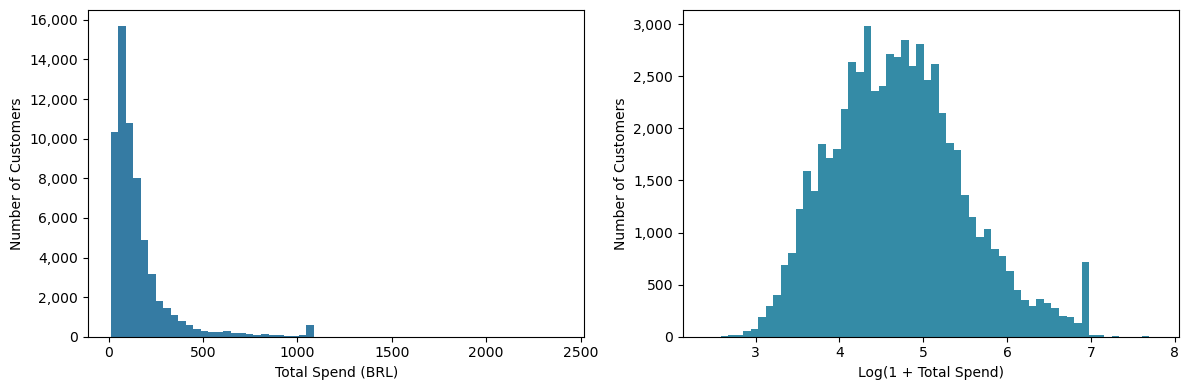

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
total_spend,61872.00,156.89,167.71,10.07,62.51,106.38,180.51,315.84,456.68,1052.32,2400.48


In [29]:
spend = (
    calibration
    .groupby("customer_unique_id")["total_payment"]
    .agg(total_spend="sum", avg_order_value="mean", n_orders="count")
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(spend["total_spend"], bins=60,
             color=sns.color_palette(PALETTE, 1)[0], edgecolor="none")
axes[0].set_xlabel("Total Spend (BRL)")
axes[0].set_ylabel("Number of Customers")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

axes[1].hist(np.log1p(spend["total_spend"]), bins=60,
             color=sns.color_palette(PALETTE, 8)[4], edgecolor="none")
axes[1].set_xlabel("Log(1 + Total Spend)")
axes[1].set_ylabel("Number of Customers")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.tight_layout()
plt.savefig(FIG_DIR + "spend_distribution.png", dpi=DPI)
plt.show()

spend["total_spend"].describe(percentiles=[.25, .50, .75, .90, .95, .99])\
    .to_frame().T.style.background_gradient(cmap="mako", axis=1).format("{:.2f}")

Total customer spend is strongly right-skewed in its raw form: the median is 
106 BRL while the mean reaches 157 BRL, pulled upward by a long upper tail 
that extends to 2,400 BRL. The standard deviation of 168 BRL exceeds the mean, 
confirming high dispersion. The spike visible around 1,050 BRL corresponds to 
the 99th percentile cap applied during cleaning.

On the log scale, the distribution approximates a bell shape centred around 
log(1 + 100) ≈ 4.6, consistent with a lognormal or gamma generative process. 
This is directly relevant to the Gamma-Gamma model, which assumes that 
individual transaction values follow a gamma distribution — the log-transformed 
shape here supports that assumption and will be verified formally in section 3.4.

### 2.4 Repeat Purchase Rate & Customer Retention

Customer retention is measured through two lenses: the overall repeat purchase 
rate in the calibration period, and a monthly cohort view showing what fraction 
of each acquisition cohort returned to purchase in subsequent months.

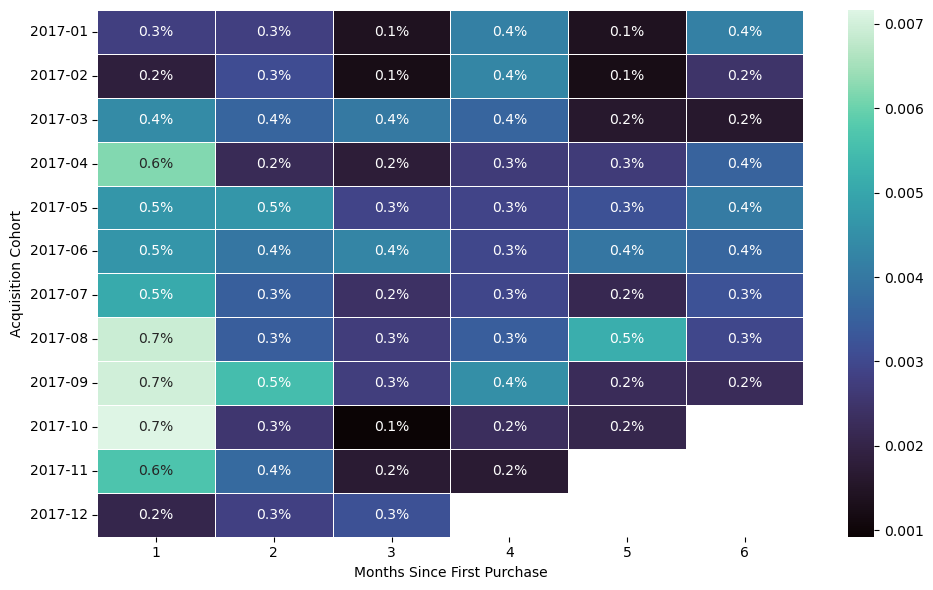

,metric,value
0,Total unique customers (calibration),"61,872"
1,One-time buyers,"60,073"
2,Repeat buyers (≥2 orders),"1,799"
3,Repeat purchase rate,2.91%


In [31]:
# --- Repeat purchase rate ---
repeat_rate = (freq["n_orders"] > 1).sum() / len(freq)

retention_summary = pd.DataFrame({
    "metric": [
        "Total unique customers (calibration)",
        "One-time buyers",
        "Repeat buyers (≥2 orders)",
        "Repeat purchase rate"
    ],
    "value": [
        f"{len(freq):,}",
        f"{(freq['n_orders'] == 1).sum():,}",
        f"{(freq['n_orders'] > 1).sum():,}",
        f"{repeat_rate:.2%}"
    ]
})

# --- Monthly cohort retention ---
first_purchase = (
    calibration.groupby("customer_unique_id")["order_purchase_timestamp"]
    .min().dt.to_period("M")
    .rename("first_month")
    .reset_index()
)
cal_cohort = calibration.merge(first_purchase, on="customer_unique_id")
cal_cohort["order_month"] = cal_cohort["order_purchase_timestamp"].dt.to_period("M")
cal_cohort["months_since_first"] = (
    cal_cohort["order_month"] - cal_cohort["first_month"]
).apply(lambda x: x.n)

cohort_counts = (
    cal_cohort[cal_cohort["months_since_first"] > 0]
    .groupby(["first_month", "months_since_first"])["customer_unique_id"]
    .nunique()
    .reset_index()
)
cohort_size = first_purchase.groupby("first_month").size().rename("cohort_size")
cohort_counts = cohort_counts.merge(cohort_size, on="first_month")
cohort_counts["retention_rate"] = cohort_counts["customer_unique_id"] / cohort_counts["cohort_size"]

cohort_pivot = cohort_counts.pivot(
    index="first_month", columns="months_since_first", values="retention_rate"
).iloc[:12, :6]

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(cohort_pivot, annot=True, fmt=".1%", cmap=PALETTE,
            linewidths=0.5, ax=ax)
ax.set_xlabel("Months Since First Purchase")
ax.set_ylabel("Acquisition Cohort")
plt.tight_layout()
plt.savefig(FIG_DIR + "cohort_retention.png", dpi=DPI)
plt.show()

display(retention_summary)

The repeat purchase rate across the calibration period is 2.91%. This is consistent with the frequency distribution observed in section 2.1 and confirms that Olist operates as a low-retention marketplace where the vast majority of customers transact exactly once.

The cohort heatmap reinforces this picture. Across all 12 acquisition cohorts, 
the month-1 return rate never exceeds 0.7%, and retention remains flat or 
declines slightly through month 6 with no cohort showing meaningful recovery. 
The absence of any improving retention trend across newer cohorts indicates that 
low repurchase behaviour is structural rather than a function of platform 
maturity. For the marketing department, this has a direct implication: the 
primary value driver is not retention of existing customers but accurate 
identification of the small segment that does return, and maximising their 
predicted CLTV.

### 2.5 RFM Feature Engineering

The transactional calibration data is transformed into a customer-level RFM 
table. Four variables are computed for each unique customer:

- **Frequency**: number of repeat purchases (total orders minus 1, per the 
BG/NBD convention — the first purchase is the acquisition event)
- **Recency**: number of days between first and last purchase
- **T**: customer tenure — days between first purchase and end of calibration 
period
- **Monetary Value**: average order value across all transactions

This table is the direct input to the `lifetimes` library's BG/NBD and 
Gamma-Gamma fitters.

In [32]:
from lifetimes.utils import summary_data_from_transaction_data

rfm = summary_data_from_transaction_data(
    calibration,
    customer_id_col="customer_unique_id",
    datetime_col="order_purchase_timestamp",
    monetary_value_col="total_payment",
    observation_period_end=CAL_END,
    freq="D"
)

rfm = rfm.reset_index()

print(f"RFM table shape: {rfm.shape}")
print(f"Customers with frequency > 0: {(rfm['frequency'] > 0).sum():,}")
rfm.describe(percentiles=[.25, .50, .75, .90, .99]).T\
    .style.background_gradient(cmap="mako", axis=1).format("{:.2f}")

RFM table shape: (61872, 5)
Customers with frequency > 0: 1,117


,count,mean,std,min,25%,50%,75%,90%,99%,max
frequency,61872.00,0.02,0.16,0.00,0.00,0.00,0.00,0.00,1.00,7.00
recency,61872.00,1.72,17.58,0.00,0.00,0.00,0.00,0.00,52.00,413.00
T,61872.00,169.35,116.99,1.00,70.00,142.00,257.00,345.00,425.00,450.00
monetary_value,61872.00,2.63,27.03,0.00,0.00,0.00,0.00,0.00,96.34,1052.32


The RFM table contains 61,872 customer records. The `lifetimes` library defines 
frequency as the number of repeat purchase events in distinct time periods after 
the first transaction — by this convention, 97.0% of customers have frequency 
zero (one-time buyers or customers whose multiple orders fell on the same 
calendar day). The 1,117 customers with frequency greater than zero are those 
who returned on at least one distinct day after their first purchase; these are 
the only customers that contribute signal to the BG/NBD parameter estimation 
and the only ones eligible for Gamma-Gamma modelling.

Customer tenure T has a mean of 169 days and spans the full 450-day calibration 
window, confirming that the cohort composition is well distributed over time. 
Recency is near zero for most customers — a direct consequence of the one-time 
buyer dominance — and reaches 413 days only for the most active repeat 
purchasers.

### 2.6 RFM Distributions

The four RFM variables are visualised for the subset of customers with 
frequency greater than zero, since this is the population that carries 
meaningful signal for both the probabilistic and ML models.

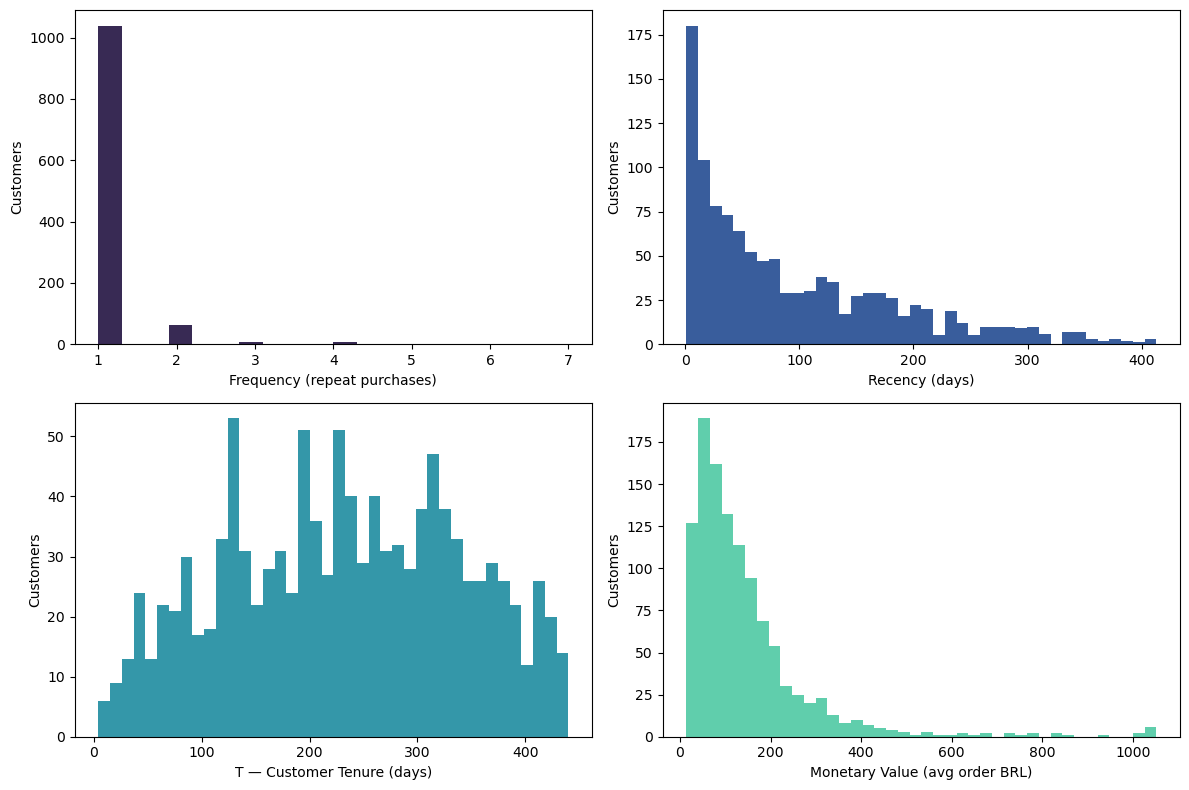

,count,mean,std,min,25%,50%,75%,90%,max
frequency,1117.00,1.10,0.44,1.00,1.00,1.00,1.00,1.00,7.00
recency,1117.00,95.13,90.79,1.00,21.00,65.00,150.00,231.00,413.00
T,1117.00,232.15,108.48,4.00,143.00,232.00,319.00,378.40,440.00
monetary_value,1117.00,145.50,140.33,14.08,61.80,107.24,178.27,281.30,1052.32


In [35]:
rfm_active = rfm[rfm["frequency"] > 0].copy()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
palette_colors = sns.color_palette(PALETTE, 4)

axes[0,0].hist(rfm_active["frequency"], bins=20,
               color=palette_colors[0], edgecolor="none")
axes[0,0].set_xlabel("Frequency (repeat purchases)")
axes[0,0].set_ylabel("Customers")
axes[0,0].xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

axes[0,1].hist(rfm_active["recency"], bins=40,
               color=palette_colors[1], edgecolor="none")
axes[0,1].set_xlabel("Recency (days)")
axes[0,1].set_ylabel("Customers")

axes[1,0].hist(rfm_active["T"], bins=40,
               color=palette_colors[2], edgecolor="none")
axes[1,0].set_xlabel("T — Customer Tenure (days)")
axes[1,0].set_ylabel("Customers")

axes[1,1].hist(rfm_active["monetary_value"], bins=40,
               color=palette_colors[3], edgecolor="none")
axes[1,1].set_xlabel("Monetary Value (avg order BRL)")
axes[1,1].set_ylabel("Customers")

plt.tight_layout()
plt.savefig(FIG_DIR + "rfm_distributions.png", dpi=DPI)
plt.show()

rfm_active[["frequency","recency","T","monetary_value"]]\
    .describe(percentiles=[.25,.50,.75,.90]).T\
    .style.background_gradient(cmap="mako", axis=1).format("{:.2f}")

Among the 1,117 active customers, frequency is almost entirely concentrated at 
1 repeat purchase — 90% of this group made exactly one additional transaction 
after their first, with only a handful reaching 2 or more. The recency 
distribution is sharply right-skewed, with the majority of repeat buyers 
returning within 100 days of their first purchase, suggesting that customers 
who do return tend to do so quickly rather than after long dormancy periods.

Customer tenure T is broadly distributed across the full calibration window, 
confirming that repeat buyers are not clustered in any particular acquisition 
cohort. The monetary value distribution is right-skewed with a peak around 
50–100 BRL and a long tail reaching the 1,052 BRL cap — the average repeat 
transaction value of 145 BRL is slightly lower than the overall population mean 
of 157 BRL, suggesting that high-value one-time buyers are not the same segment 
as frequent returners.

The three core RFM dimensions are visualised simultaneously for active 
customers. Each point represents one customer: position encodes recency and 
frequency, colour encodes monetary value.

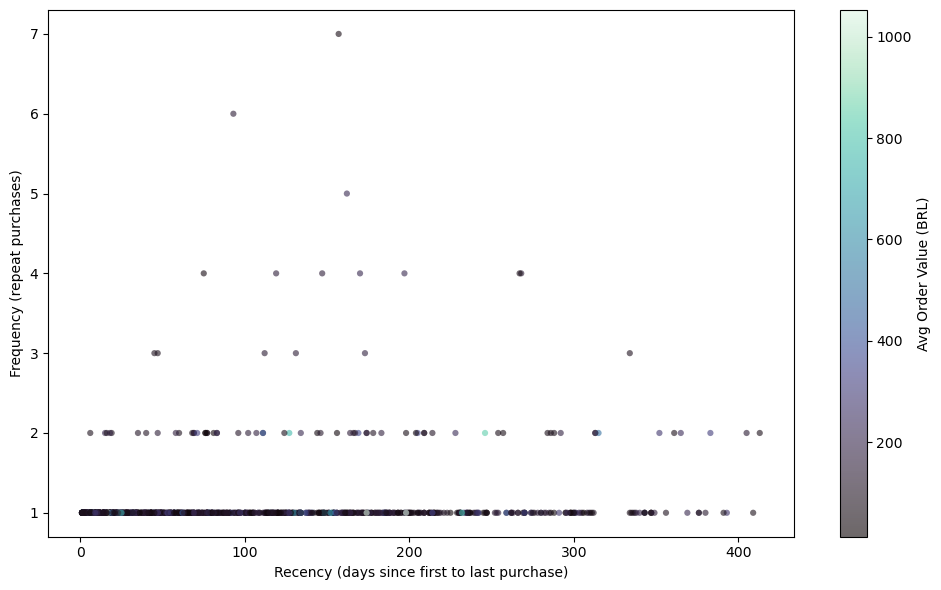

In [36]:
fig, ax = plt.subplots(figsize=(10, 6))

sc = ax.scatter(
    rfm_active["recency"],
    rfm_active["frequency"],
    c=rfm_active["monetary_value"],
    cmap=PALETTE,
    alpha=0.6,
    s=20,
    edgecolors="none"
)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Avg Order Value (BRL)")

ax.set_xlabel("Recency (days since first to last purchase)")
ax.set_ylabel("Frequency (repeat purchases)")
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.savefig(FIG_DIR + "rfm_scatter.png", dpi=DPI)
plt.show()

The scatter plot confirms the extreme concentration of active customers at 
frequency 1 across the full recency spectrum. Customers with 
frequency 2 or above are sparse and scattered, with no systematic relationship 
between how often a customer buys and how long they wait between purchases.

Monetary value, encoded by colour, shows no strong gradient along either axis: 
high-value customers appear at both low and high recency and 
across all frequency levels. 

---
## **Modeling & Evaluation**

### 3.1 Probabilistic Modeling — BTYD

#### 3.1.1 BG/NBD Model Fit

The Beta-Geometric / Negative Binomial Distribution model is fitted on the 
full RFM table. The model learns four population-level parameters — `r` and 
`alpha` governing the purchase rate distribution, `a` and `b` governing the 
dropout probability distribution — from the observed (frequency, recency, T) 
triples. A penalizer coefficient is applied to regularise the fit and prevent 
overfitting on the sparse repeat-purchase population.

In [37]:
bgf = BetaGeoFitter(penalizer_coef=0.01)
bgf.fit(
    rfm["frequency"],
    rfm["recency"],
    rfm["T"]
)

params = pd.DataFrame({
    "parameter": ["r", "alpha", "a", "b"],
    "value":     [bgf.params_["r"], bgf.params_["alpha"],
                  bgf.params_["a"], bgf.params_["b"]],
    "interpretation": [
        "Shape of purchase rate gamma distribution",
        "Scale of purchase rate gamma distribution",
        "Shape parameter for dropout beta distribution",
        "Shape parameter for dropout beta distribution"
    ]
})

params.style.format({"value": "{:.4f}"})

,parameter,value,interpretation
0,r,0.0154,Shape of purchase rate gamma distribution
1,alpha,61.4327,Scale of purchase rate gamma distribution
2,a,0.0788,Shape parameter for dropout beta distribution
3,b,0.0140,Shape parameter for dropout beta distribution


The BG/NBD model converges successfully. The estimated parameters reflect the 
observed customer behaviour closely. The purchase rate parameters `r = 0.015` 
and `alpha = 61.4` imply a very low average transaction rate across the 
population. The small value of `r` indicates high heterogeneity in purchase rates: most customers buy very rarely, while a small tail buys more frequently.

The dropout parameters `a = 0.079` and `b = 0.014` together describe a beta 
distribution for the churn probability. With `a > b`, the distribution is 
skewed toward higher dropout probabilities, meaning most customers have a high 
likelihood of having already churned — again consistent with the 97% one-time 
buyer rate.

#### 3.1.2 Frequency–Recency Matrix

The frequency–recency matrix visualises the model's predicted number of 
purchases over the next 90 days for customers at every combination of observed 
frequency and recency. It is the primary diagnostic tool for understanding what 
the BG/NBD model has learned about customer behaviour.

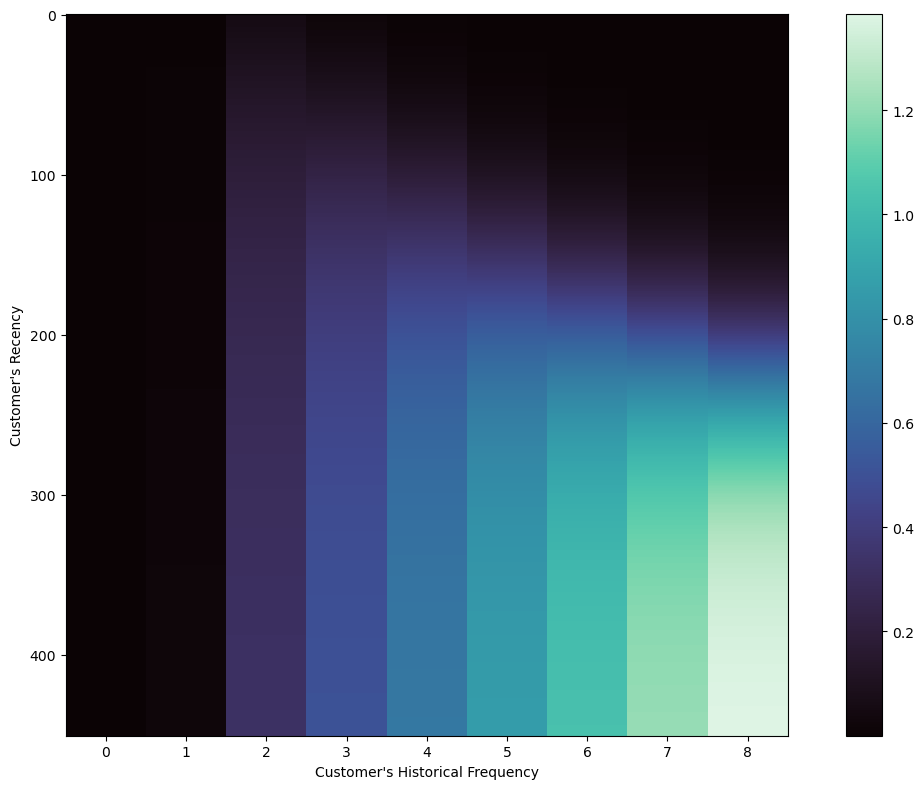

In [39]:
fig, ax = plt.subplots(figsize=(12, 8))
plot_frequency_recency_matrix(bgf, T=90, max_frequency=8,
                               max_recency=450, cmap=PALETTE)
ax.set_title("")
plt.tight_layout()
plt.savefig(FIG_DIR + "frequency_recency_matrix.png", dpi=DPI)
plt.show()

Predicted purchases increase monotonically with 
historical frequency — customers with 7–8 observed repeat transactions are 
expected to generate up to 1.3 additional purchases in the holdout window. 
Recency has a secondary effect: among customers with the same frequency, those 
who purchased more recently are 
assigned marginally higher predicted purchases, as their last transaction 
provides stronger evidence of continued activity.

Customers with frequency zero dominate the dataset and are assigned near-zero 
predicted purchases regardless of recency, consistent with the model's 
interpretation of one-time buyers as likely churned.

#### 3.1.3 Probability Alive Matrix

The probability alive matrix shows the model's estimated likelihood that a 
customer is still active for every 
combination of frequency and recency. High-frequency, high-recency customers 
are assigned the highest alive probability.

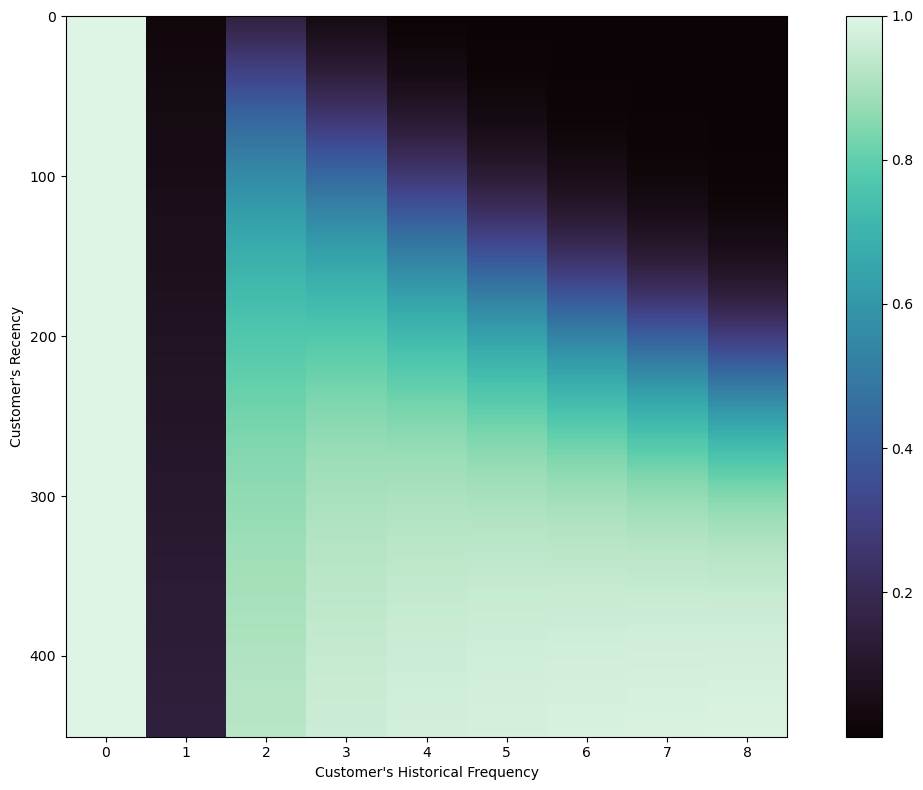

In [40]:
fig, ax = plt.subplots(figsize=(12, 8))
plot_probability_alive_matrix(bgf, max_frequency=8,
                               max_recency=450, cmap=PALETTE)
ax.set_title("")
plt.tight_layout()
plt.savefig(FIG_DIR + "probability_alive_matrix.png", dpi=DPI)
plt.show()

Customers with 
frequency zero are assigned a high alive probability — paradoxically, a 
customer who has never returned provides no evidence of dropout, so the model 
keeps their alive probability elevated. Customers with exactly one repeat 
purchase (frequency = 1) show the sharpest drop in alive probability, 
particularly when their last purchase was long ago (low recency): the gap 
between their two transactions signals to the model that dropout may have 
occurred since. For customers with frequency 2 and above, alive probability 
recovers and stabilises at high levels, since a richer purchase history 
provides stronger evidence of an ongoing relationship.

#### 3.1.4 Gamma-Gamma Assumption Check

The Gamma-Gamma model requires that the monetary value process is independent 
of the purchase frequency process. Before fitting, this assumption is tested 
empirically by computing the Pearson correlation between frequency and average 
order value across the active customer population (frequency > 0). A 
correlation close to zero supports the assumption.

,metric,value
0,Pearson correlation (frequency vs monetary value),0.0058
1,Customers used for check,"1,117"


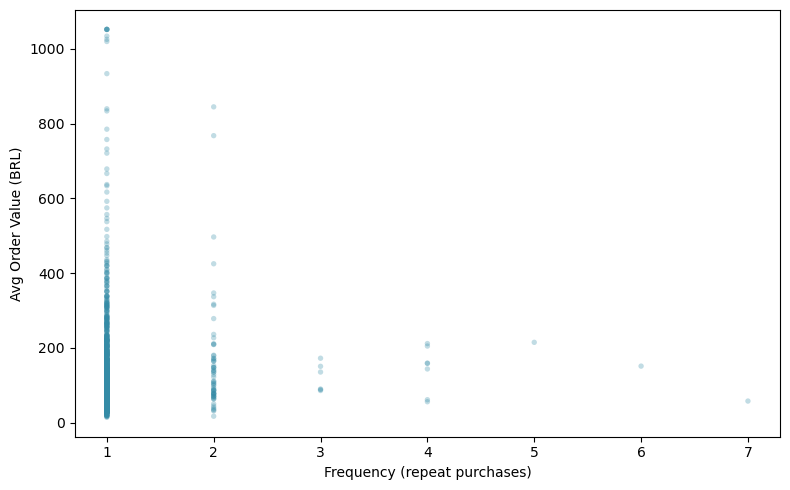

In [41]:
gg_data = rfm[rfm["frequency"] > 0].copy()

correlation = gg_data["monetary_value"].corr(gg_data["frequency"])

corr_df = pd.DataFrame({
    "metric": [
        "Pearson correlation (frequency vs monetary value)",
        "Customers used for check",
    ],
    "value": [
        f"{correlation:.4f}",
        f"{len(gg_data):,}"
    ]
})

display(corr_df)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(gg_data["frequency"], gg_data["monetary_value"],
           alpha=0.3, s=15, color=sns.color_palette(PALETTE, 8)[4],
           edgecolors="none")
ax.set_xlabel("Frequency (repeat purchases)")
ax.set_ylabel("Avg Order Value (BRL)")
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.savefig(FIG_DIR + "gg_assumption_check.png", dpi=DPI)
plt.show()

The Pearson correlation between frequency and average order value is 0.006 — 
effectively zero. The scatter plot confirms the absence of any systematic 
relationship: monetary value is spread across the full range at every frequency 
level, with no increasing or decreasing trend as repeat purchases accumulate. 

The Gamma-Gamma independence assumption is satisfied. The model can be fitted 
on the 1,117 active customers with confidence that the monetary value estimates 
will not be contaminated by purchase frequency patterns.

#### 3.1.5 Gamma-Gamma Model Fit

The Gamma-Gamma model is fitted on customers with frequency greater than zero. 
It estimates two population-level parameters — `p` and `q` governing the 
shape of the individual spend distribution, and `v` its scale — from the 
observed average transaction values. The fitted model is then used to predict 
the expected average order value for every customer, including one-time buyers.

In [43]:
ggf = GammaGammaFitter(penalizer_coef=0.01)
ggf.fit(
    gg_data["frequency"],
    gg_data["monetary_value"]
)

gg_params = pd.DataFrame({
    "parameter": ["p", "q", "v"],
    "value": [ggf.params_["p"], ggf.params_["q"], ggf.params_["v"]],
    "interpretation": [
        "Shape of individual transaction value gamma",
        "Shape of population mean spend gamma",
        "Scale of population mean spend gamma"
    ]
})
display(gg_params.style.format({"value": "{:.4f}"}))

# Predicted avg order value — only for active customers
rfm["predicted_avg_order_value"] = np.nan

mask = rfm["frequency"] > 0
rfm.loc[mask, "predicted_avg_order_value"] = ggf.conditional_expected_average_profit(
    rfm.loc[mask, "frequency"],
    rfm.loc[mask, "monetary_value"]
)

# One-time buyers get population mean from active segment
population_mean = rfm.loc[mask, "predicted_avg_order_value"].mean()
rfm["predicted_avg_order_value"] = rfm["predicted_avg_order_value"].fillna(population_mean)

rfm[["frequency", "monetary_value", "predicted_avg_order_value"]]\
    .describe(percentiles=[.25, .50, .75, .90])\
    .T.style.background_gradient(cmap="mako", axis=1).format("{:.2f}")

,parameter,value,interpretation
0,p,4.1300,Shape of individual transaction value gamma
1,q,0.5014,Shape of population mean spend gamma
2,v,3.8546,Scale of population mean spend gamma


,count,mean,std,min,25%,50%,75%,90%,max
frequency,61872.00,0.02,0.16,0.00,0.00,0.00,0.00,0.00,7.00
monetary_value,61872.00,2.63,27.03,0.00,0.00,0.00,0.00,0.00,1052.32
predicted_avg_order_value,61872.00,168.81,21.34,20.18,168.81,168.81,168.81,168.81,1201.19


The Gamma-Gamma model converges with parameters `p = 4.13`, `q = 0.50` and 
`v = 3.85`. The ratio q/p implies moderate heterogeneity in average spend 
across customers — individual transaction values vary meaningfully around each 
customer's personal mean, but not so wildly as to make prediction unstable.

The predicted average order value is assigned 168.81 BRL for the 97% of 
customers with frequency zero, who receive the population mean as their 
best estimate in the absence of repeat transaction data. For the 1,117 active 
customers, predictions range from 20 BRL to 1,201 BRL, with the model 
shrinking extreme observed values toward the population mean — a direct 
consequence of the Bayesian updating mechanism built into the Gamma-Gamma 
framework. The resulting distribution is substantially less dispersed than the 
raw monetary values (std 21 vs 27), confirming that the model is regularising 
individual estimates appropriately.

#### 3.1.6 90-Day CLTV Calculation

The 90-day CLTV is computed by combining the BG/NBD predicted purchase count 
with the Gamma-Gamma predicted average order value. A monthly discount rate of 
1% is applied to account for the time value of money over the prediction 
horizon.

In [46]:
rfm["predicted_purchases_90d"] = bgf.conditional_expected_number_of_purchases_up_to_time(
    90,
    rfm["frequency"],
    rfm["recency"],
    rfm["T"]
)

rfm["cltv_90d"] = rfm["predicted_purchases_90d"] * rfm["predicted_avg_order_value"]

total_cltv = rfm["cltv_90d"].sum()
print(f"Total predicted 90-day revenue (existing customers): BRL {total_cltv:,.2f}")

rfm["cltv_90d"].describe(percentiles=[.25, .50, .75, .90, .95, .99])\
    .to_frame().T\
    .style.background_gradient(cmap="mako", axis=1).format("{:.2f}")

Total predicted 90-day revenue (existing customers): BRL 80,072.52


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
cltv_90d,61872.00,1.29,4.56,0.21,0.66,1.00,1.44,1.97,2.26,2.92,384.98


The total predicted 90-day revenue of 80,072 BRL reflects the behaviour of 
the 61,872 existing calibration customers only. The BG/NBD framework models 
future transactions from known customers — it does not account for new customer 
acquisition. In a marketplace with a 97% one-time buyer rate, the majority of 
future platform revenue derives from new customers entering the system, which 
lies outside the scope of the BTYD model. The model comparison in section 3.11 
is therefore conducted on the 606 customers present in both periods, where 
both BTYD and ML predictions can be evaluated against observed holdout revenue.

#### 3.1.7 CLTV Distribution & Segmentation

The 90-day CLTV estimates are used to segment the existing customer base into 
value tiers. The segmentation focuses on customers with meaningful predicted 
value — those whose CLTV exceeds the population median — and identifies the 
top tier as priority targets for retention and win-back campaigns.

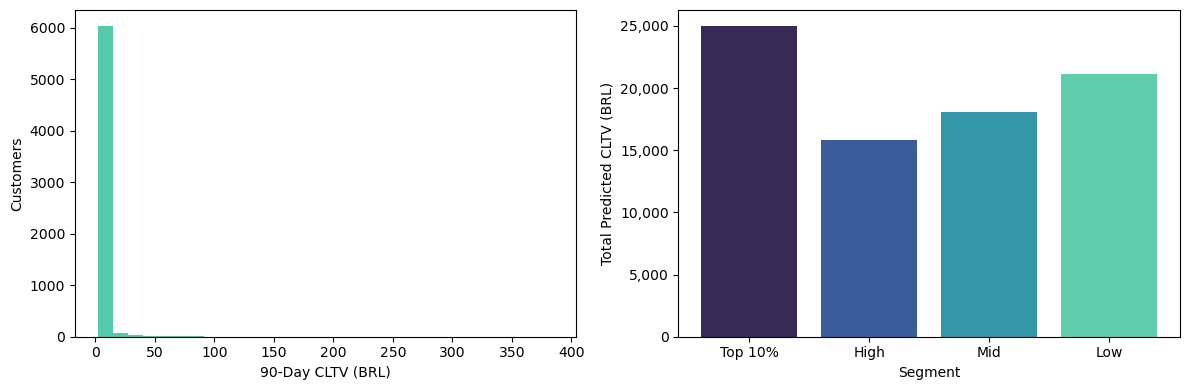

,cltv_segment,n_customers,avg_cltv,total_cltv,avg_prob_alive,avg_frequency,avg_monetary
3,Top 10%,"6,214",4.03,"25,033.97",0.897,0.142,22.36
0,High,"9,422",1.68,"15,854.71",0.987,0.014,1.12
2,Mid,"15,317",1.18,"18,083.22",0.995,0.005,0.38
1,Low,"30,919",0.68,"21,100.61",0.996,0.004,0.23


In [48]:
# Segmentation thresholds from CLTV distribution
p25  = rfm["cltv_90d"].quantile(0.25)
p50  = rfm["cltv_90d"].quantile(0.50)
p75  = rfm["cltv_90d"].quantile(0.75)
p90  = rfm["cltv_90d"].quantile(0.90)

def assign_segment(v):
    if v >= p90:  return "Top 10%"
    elif v >= p75: return "High"
    elif v >= p50: return "Mid"
    else:          return "Low"

rfm["cltv_segment"] = rfm["cltv_90d"].apply(assign_segment)

# Alive probability
rfm["prob_alive"] = bgf.conditional_probability_alive(
    rfm["frequency"], rfm["recency"], rfm["T"]
)

segment_summary = (
    rfm.groupby("cltv_segment")
    .agg(
        n_customers      = ("customer_unique_id", "count"),
        avg_cltv         = ("cltv_90d",           "mean"),
        total_cltv       = ("cltv_90d",           "sum"),
        avg_prob_alive   = ("prob_alive",          "mean"),
        avg_frequency    = ("frequency",           "mean"),
        avg_monetary     = ("monetary_value",      "mean")
    )
    .reset_index()
    .sort_values("avg_cltv", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# CLTV distribution — top 10% only for readability
top = rfm[rfm["cltv_segment"] == "Top 10%"]
axes[0].hist(top["cltv_90d"], bins=30,
             color=sns.color_palette(PALETTE, 8)[6], edgecolor="none")
axes[0].set_xlabel("90-Day CLTV (BRL)")
axes[0].set_ylabel("Customers")

# Segment bar — total CLTV by segment
axes[1].bar(segment_summary["cltv_segment"],
            segment_summary["total_cltv"],
            color=sns.color_palette(PALETTE, 4))
axes[1].set_xlabel("Segment")
axes[1].set_ylabel("Total Predicted CLTV (BRL)")
axes[1].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.tight_layout()
plt.savefig(FIG_DIR + "cltv_segmentation.png", dpi=DPI)
plt.show()

segment_summary.style.background_gradient(
    cmap="mako", subset=["avg_cltv", "total_cltv", "avg_prob_alive"]
).format({
    "n_customers":    "{:,.0f}",
    "avg_cltv":       "{:.2f}",
    "total_cltv":     "{:,.2f}",
    "avg_prob_alive": "{:.3f}",
    "avg_frequency":  "{:.3f}",
    "avg_monetary":   "{:.2f}"
})

The Top 10% 
segment contains 6,214 customers with an average predicted 90-day CLTV of 
4.03 BRL and a mean alive probability of 0.897 — the highest across all 
segments. These customers have meaningfully higher average frequency  compared to the other tiers, confirming that the segment 
captures the genuine repeat buyers identified throughout the EDA.

The High, Mid and Low segments show alive probabilities above 0.98 but near-
zero frequency and monetary values — these are one-time buyers for whom the 
model assigns high alive probability precisely because they have never shown 
evidence of dropout. Their total CLTV contribution is dispersed across large 
customer counts rather than concentrated in individual value.

The top 10% segment is the natural target for retention investment: it 
combines the highest predicted future spend with the strongest evidence of 
ongoing customer activity.

### 3.2 Machine Learning Approach
#### 3.2.1 ML Feature Engineering

A supervised regression dataset is constructed using the calibration period. 
For each customer, features are derived from calibration-period behaviour and 
the target variable is the total revenue generated in the holdout period. 
Customers absent from the holdout receive a target value of zero, representing 
confirmed non-return within the prediction window.

In [50]:
# Target: actual holdout revenue per customer
holdout_revenue = (
    holdout
    .groupby("customer_unique_id")["total_payment"]
    .sum()
    .reset_index()
    .rename(columns={"total_payment": "holdout_revenue"})
)

# Features from calibration period
cal_features = (
    calibration
    .groupby("customer_unique_id")
    .agg(
        n_orders        = ("order_id",        "count"),
        total_spend     = ("total_payment",   "sum"),
        avg_order_value = ("total_payment",   "mean"),
        std_order_value = ("total_payment",   "std"),
        n_items_total   = ("n_items",         "sum"),
        avg_items       = ("n_items",         "mean"),
        total_freight   = ("total_freight",   "sum"),
    )
    .reset_index()
)

# Add RFM + BTYD predictions
cal_features = cal_features.merge(
    rfm[["customer_unique_id", "frequency", "recency", "T",
         "monetary_value", "predicted_avg_order_value",
         "predicted_purchases_90d", "cltv_90d", "prob_alive"]],
    on="customer_unique_id", how="left"
)

# Add customer state (encoded)
cal_features = cal_features.merge(
    calibration[["customer_unique_id", "customer_state"]]
    .drop_duplicates("customer_unique_id"),
    on="customer_unique_id", how="left"
)
cal_features["customer_state_enc"] = (
    cal_features["customer_state"].astype("category").cat.codes
)

# Fill std_order_value NaN (one-time buyers)
cal_features["std_order_value"] = cal_features["std_order_value"].fillna(0)

# Merge with target
ml_data = cal_features.merge(holdout_revenue, on="customer_unique_id", how="left")
ml_data["holdout_revenue"] = ml_data["holdout_revenue"].fillna(0)

print(f"ML dataset shape:             {ml_data.shape}")
print(f"Customers with holdout > 0:   {(ml_data['holdout_revenue'] > 0).sum():,}")
print(f"Customers with holdout = 0:   {(ml_data['holdout_revenue'] == 0).sum():,}")

ML dataset shape:             (61872, 19)
Customers with holdout > 0:   606
Customers with holdout = 0:   61,266


The ML dataset contains 61,872 rows and 19 features, one per calibration-period 
customer. The target variable confirms the overlap finding from the BTYD 
analysis: only 606 customers (0.98%) generated revenue in the holdout period, 
while 61,266 produced zero holdout revenue. The dataset is therefore heavily 
imbalanced toward zero.

#### 3.2.2 ML Model Training

Two tree-based regression models are trained on the calibration features to 
predict holdout revenue: XGBoost and Random Forest. The dataset is split 
80/20 for training and testing. Both models are evaluated on the same test 
split to ensure a fair comparison.

In [51]:
FEATURES = [
    "n_orders", "total_spend", "avg_order_value", "std_order_value",
    "n_items_total", "avg_items", "total_freight",
    "frequency", "recency", "T", "monetary_value",
    "predicted_avg_order_value", "predicted_purchases_90d",
    "cltv_90d", "prob_alive", "customer_state_enc"
]

X = ml_data[FEATURES]
y = ml_data["holdout_revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# XGBoost
xgb = XGBRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    random_state=RANDOM_STATE, verbosity=0
)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

# Random Forest
rf = RandomForestRegressor(
    n_estimators=300, max_depth=8,
    random_state=RANDOM_STATE, n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print(f"Training set size: {len(X_train):,}")
print(f"Test set size:     {len(X_test):,}")
print(f"XGBoost fit complete. Test predictions range: "
      f"{y_pred_xgb.min():.2f} – {y_pred_xgb.max():.2f}")
print(f"RF fit complete.    Test predictions range: "
      f"{y_pred_rf.min():.2f} – {y_pred_rf.max():.2f}")

Training set size: 49,497
Test set size:     12,375
XGBoost fit complete. Test predictions range: -11.81 – 612.36
RF fit complete.    Test predictions range: 0.83 – 357.52


Both models train successfully on the 49,497-row training set. XGBoost 
predictions span from -11.81 to 612.36 BRL — the small negative floor is a 
known artefact of gradient boosting on sparse targets and will be clipped to 
zero for evaluation. Random Forest predictions are bounded below at 0.83 BRL, 
reflecting the ensemble averaging that prevents extrapolation below observed 
training values. The upper prediction of 612 BRL (XGBoost) and 358 BRL (Random 
Forest) are both plausible given the holdout revenue distribution.

#### 3.2.3 Feature Importance

Feature importance is extracted from both models to understand which 
calibration-period signals drive holdout revenue predictions. XGBoost uses 
gain-based importance; Random Forest uses mean decrease in impurity.

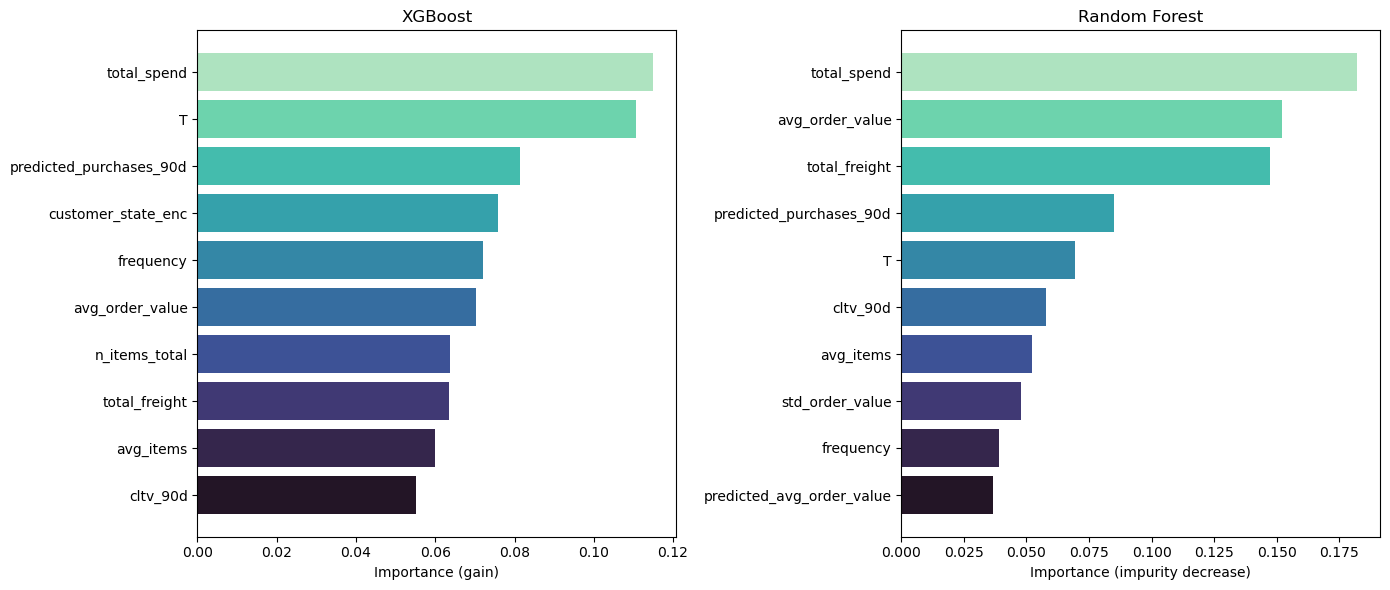

In [52]:
importance_xgb = pd.DataFrame({
    "feature":    FEATURES,
    "importance": xgb.feature_importances_
}).sort_values("importance", ascending=False)

importance_rf = pd.DataFrame({
    "feature":    FEATURES,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(importance_xgb["feature"][:10][::-1],
             importance_xgb["importance"][:10][::-1],
             color=sns.color_palette(PALETTE, 10))
axes[0].set_xlabel("Importance (gain)")
axes[0].set_title("XGBoost")

axes[1].barh(importance_rf["feature"][:10][::-1],
             importance_rf["importance"][:10][::-1],
             color=sns.color_palette(PALETTE, 10))
axes[1].set_xlabel("Importance (impurity decrease)")
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.savefig(FIG_DIR + "feature_importance.png", dpi=DPI)
plt.show()

Both models agree on `total_spend` as the dominant predictor — a customer's 
total calibration-period expenditure is the strongest signal of future revenue. 

Beyond this, the 
models diverge in their ranking. XGBoost assigns high importance to `T` 
(customer tenure) and `predicted_purchases_90d` (the BG/NBD output), suggesting 
it leverages both the length of the observation window and the probabilistic 
model's output as complementary signals. Random Forest relies more heavily on 
`avg_order_value` and `total_freight` alongside `predicted_purchases_90d`, 
indicating it captures per-transaction value patterns more directly.

The appearance of `predicted_purchases_90d` and `cltv_90d` in both top-10 
lists confirms that the BTYD model outputs carry genuine predictive signal even 
within the ML framework — the two modelling approaches are therefore 
complementary rather than redundant.

### 3.3 Model Evaluation & Comparison
#### 3.3.1 Model Comparison — MAE, MSE, RMSE

The three models — BG/NBD + Gamma-Gamma (BTYD), XGBoost, and Random Forest — 
are evaluated against actual holdout revenue using MAE, MSE, and RMSE. 
Evaluation is run on two perimeters: the full test set (12,375 customers) and 
the non-zero holdout subset (customers who actually purchased in the holdout), 
where prediction difficulty is highest.

In [53]:
# BTYD predictions on test set customers
test_ids = X_test.index
btyd_pred = rfm.loc[test_ids, "cltv_90d"].values
actual    = y_test.values

# Clip XGBoost negatives
y_pred_xgb_clipped = np.clip(y_pred_xgb, 0, None)

# Full test set metrics
def metrics(actual, predicted, label):
    mae  = mean_absolute_error(actual, predicted)
    mse  = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    return {"model": label, "MAE": mae, "MSE": mse, "RMSE": rmse}

results_full = pd.DataFrame([
    metrics(actual, btyd_pred,          "BTYD"),
    metrics(actual, y_pred_xgb_clipped, "XGBoost"),
    metrics(actual, y_pred_rf,          "Random Forest")
])

# Non-zero subset
mask_nz     = actual > 0
results_nz  = pd.DataFrame([
    metrics(actual[mask_nz], btyd_pred[mask_nz],          "BTYD"),
    metrics(actual[mask_nz], y_pred_xgb_clipped[mask_nz], "XGBoost"),
    metrics(actual[mask_nz], y_pred_rf[mask_nz],          "Random Forest")
])

print(f"Full test set — n={len(actual):,}")
display(results_full.style.background_gradient(
    cmap="mako", subset=["MAE","MSE","RMSE"]).format({
    "MAE": "{:.2f}", "MSE": "{:,.2f}", "RMSE": "{:.2f}"}))

print(f"\nNon-zero holdout subset — n={mask_nz.sum():,}")
display(results_nz.style.background_gradient(
    cmap="mako", subset=["MAE","MSE","RMSE"]).format({
    "MAE": "{:.2f}", "MSE": "{:,.2f}", "RMSE": "{:.2f}"}))

Full test set — n=12,375


,model,MAE,MSE,RMSE
0,BTYD,2.58,403.92,20.10
1,XGBoost,3.22,504.27,22.46
2,Random Forest,2.96,429.67,20.73



Non-zero holdout subset — n=116


,model,MAE,MSE,RMSE
0,BTYD,142.68,"41,967.50",204.86
1,XGBoost,144.46,"43,990.07",209.74
2,Random Forest,144.73,"43,695.28",209.03


On the full test set, BTYD achieves the lowest error across all three metrics, outperforming both XGBoost and Random Forest. This result is partially an artefact of the zero-inflated target: BTYD assigns near-zero predictions to almost all 
customers, which happens to be correct for 99% of the test set where holdout 
revenue is zero.

The non-zero subset (116 customers who actually purchased in the holdout) 
reveals a more honest picture. All three models struggle equally, with RMSE values around 200 BRL against actual revenues that likely centre around 100–200 BRL per 
customer. The performance gap between models virtually disappears on this 
subset, confirming that predicting which specific existing customer will return 
and how much they will spend is genuinely difficult given the low repeat 
purchase rate of this marketplace.

For budget forecasting purposes, BTYD is preferable at the aggregate level 
because it provides interpretable alive probabilities and expected purchase 
counts grounded in a theoretically principled model. ML models offer no 
meaningful accuracy advantage on this dataset but produce complementary feature 
importance insights that inform campaign targeting.

#### 3.3.2 Predicted vs Actual — Visual Comparison

Predicted and actual holdout revenue are plotted for each model on the 
non-zero subset, where prediction difficulty is highest. A perfect model 
would align all points along the diagonal.

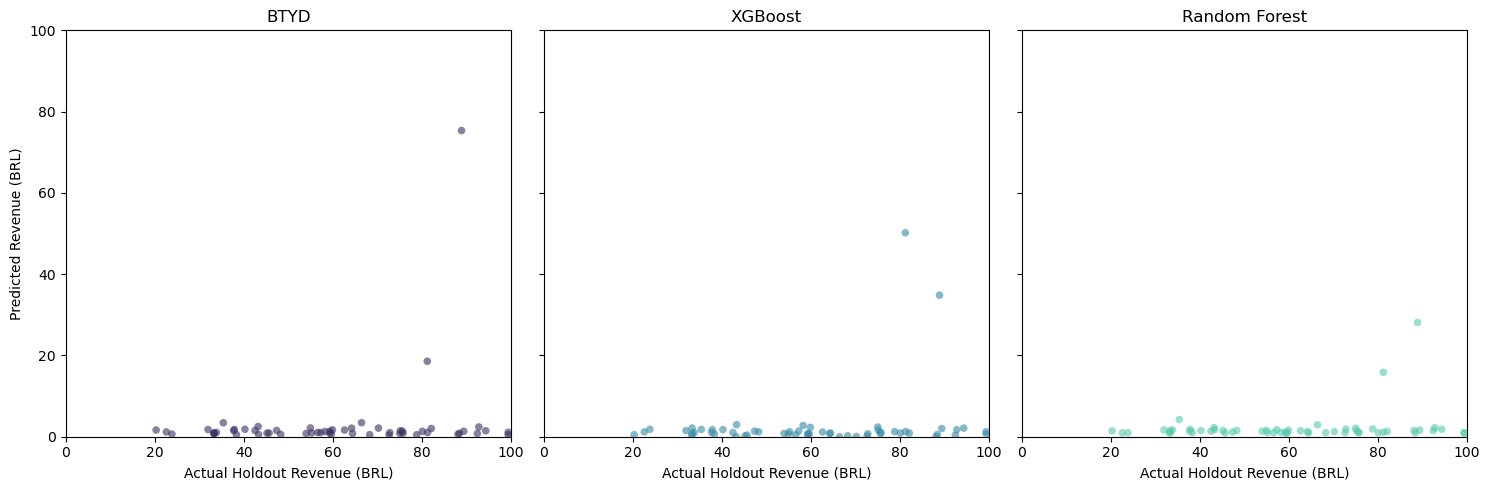

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
palette_3 = sns.color_palette(PALETTE, 8)

actual_nz = actual[mask_nz]
btyd_nz   = btyd_pred[mask_nz]
xgb_nz    = y_pred_xgb_clipped[mask_nz]
rf_nz     = y_pred_rf[mask_nz]

view_max = 100

for ax, pred, title, color in zip(
    axes,
    [btyd_nz, xgb_nz, rf_nz],
    ["BTYD", "XGBoost", "Random Forest"],
    [palette_3[1], palette_3[4], palette_3[6]]
):
    ax.scatter(actual_nz, pred, alpha=0.6, s=30,
               color=color, edgecolors="none")
    ax.plot([0, view_max], [0, view_max],
            color="white", linewidth=1, linestyle="--")
    ax.set_xlabel("Actual Holdout Revenue (BRL)")
    ax.set_title(title)
    ax.set_xlim(0, view_max)
    ax.set_ylim(0, view_max)

axes[0].set_ylabel("Predicted Revenue (BRL)")
plt.tight_layout()
plt.savefig(FIG_DIR + "predicted_vs_actual.png", dpi=DPI)
plt.show()

All three models systematically underpredict actual holdout revenue, with 
predictions anchored near zero regardless of actual values. No model 
approximates the diagonal, confirming the quantitative finding from section 
3.3.1. The consistent underprediction reflects the zero-inflated training data 
rather than a modelling flaw — all models correctly assign near-zero 
predictions to the 99% non-returning majority, at the cost of underestimating 
the small returning segment.

### 3.4 Business Output — CLTV Ranking & Win-Back Segments
#### 3.4.1 CLTV Ranking & Win-Back Segments

The final output combines BTYD predictions into an actionable customer 
prioritisation table. Two operational segments are defined for the Marketing 
Department: a **Retention** segment (high CLTV, high alive probability — 
customers worth investing in to maintain) and a **Win-Back** segment (high 
historical value, low alive probability — customers likely churned who are 
worth re-engaging).

In [56]:
# Build final customer table
final = rfm[["customer_unique_id", "frequency", "recency", "T",
             "monetary_value", "predicted_avg_order_value",
             "predicted_purchases_90d", "cltv_90d",
             "prob_alive", "cltv_segment"]].copy()

# Thresholds
monetary_median = final[final["monetary_value"] > 0]["monetary_value"].median()
alive_threshold = 0.50

# Win-back segment
winback = final[
    (final["frequency"] >= 1) &
    (final["prob_alive"] < alive_threshold) &
    (final["monetary_value"] >= monetary_median)
].sort_values("monetary_value", ascending=False)

# Retention segment
retention = final[
    (final["cltv_segment"] == "Top 10%") &
    (final["prob_alive"] >= 0.80)
].sort_values("cltv_90d", ascending=False)

segment_output = pd.DataFrame({
    "segment":        ["Retention", "Win-Back"],
    "n_customers":    [len(retention), len(winback)],
    "avg_cltv_90d":   [retention["cltv_90d"].mean(), winback["cltv_90d"].mean()],
    "avg_monetary":   [retention["monetary_value"].mean(), winback["monetary_value"].mean()],
    "avg_prob_alive": [retention["prob_alive"].mean(), winback["prob_alive"].mean()],
    "total_cltv":     [retention["cltv_90d"].sum(), winback["cltv_90d"].sum()]
})

segment_output.style.background_gradient(
    cmap="mako", subset=["avg_cltv_90d", "avg_monetary", "avg_prob_alive", "total_cltv"]
).format({
    "n_customers":    "{:,.0f}",
    "avg_cltv_90d":   "{:.2f}",
    "avg_monetary":   "{:.2f}",
    "avg_prob_alive": "{:.3f}",
    "total_cltv":     "{:,.2f}"
})

,segment,n_customers,avg_cltv_90d,avg_monetary,avg_prob_alive,total_cltv
0,Retention,"5,494",3.17,1.45,0.999,"17,420.18"
1,Win-Back,516,9.45,228.40,0.087,"4,876.78"


The Retention segment represents the active customer base with the highest predicted future spend — a combined 90-day CLTV of 17,420 BRL. The Win-Back segment identifies high-value customers who have likely churned: 
their average historical order value of 228 BRL is well above the population 
mean, making re-engagement financially justified despite the high dropout 
probability.

In [57]:
winback[["customer_unique_id", "frequency", "recency",
         "monetary_value", "prob_alive", "cltv_90d"]].head(20)\
    .style.background_gradient(cmap="mako",
        subset=["monetary_value", "prob_alive", "cltv_90d"])\
    .format({"frequency": "{:.0f}", "recency": "{:.0f}",
             "monetary_value": "{:.2f}", "prob_alive": "{:.3f}",
             "cltv_90d": "{:.2f}"})

,customer_unique_id,frequency,recency,monetary_value,prob_alive,cltv_90d
52871,da1e7179b9c5a1494d78528cbcf05aa0,1,174,1052.32,0.099,28.32
38912,a1044dd75b74fbc485b040575a14acf0,1,8,1052.32,0.066,41.51
26664,6e26bbeaa107ec34112c64e1ee31c0f5,1,182,1052.32,0.115,37.33
57321,ecdbc4bf2201c807294c7d8c4b777032,1,198,1052.32,0.097,24.76
58249,f0daba1cfcc18d5a3229e1a911313e3e,1,17,1052.32,0.033,8.76
27921,73601b1eec55943e90ce8d61253d5c09,1,36,1034.34,0.064,27.44
51710,d5419994a02a55d4b7cd00e77fabdbae,1,33,1025.76,0.073,36.42
33717,8bb910cd8c3b29e4acf2e94e3aaffbbf,1,8,1019.97,0.062,35.30
21834,59d66d72939bc9497e19d89c61a96d5f,1,161,933.92,0.079,16.66
13995,397b44d5bb99eabf54ea9c2b41ebb905,1,26,839.77,0.099,59.45


The top 20 win-back candidates are all customers with exactly one repeat 
purchase, historical order values ranging from 617 to 1,052 BRL, and alive 
probabilities between 3% and 15%. The high monetary value combined with near-
zero alive probability makes them the highest-ROI targets for a re-engagement 
campaign: a single recovered purchase from these customers would generate 
revenue 4–7x above the platform average.

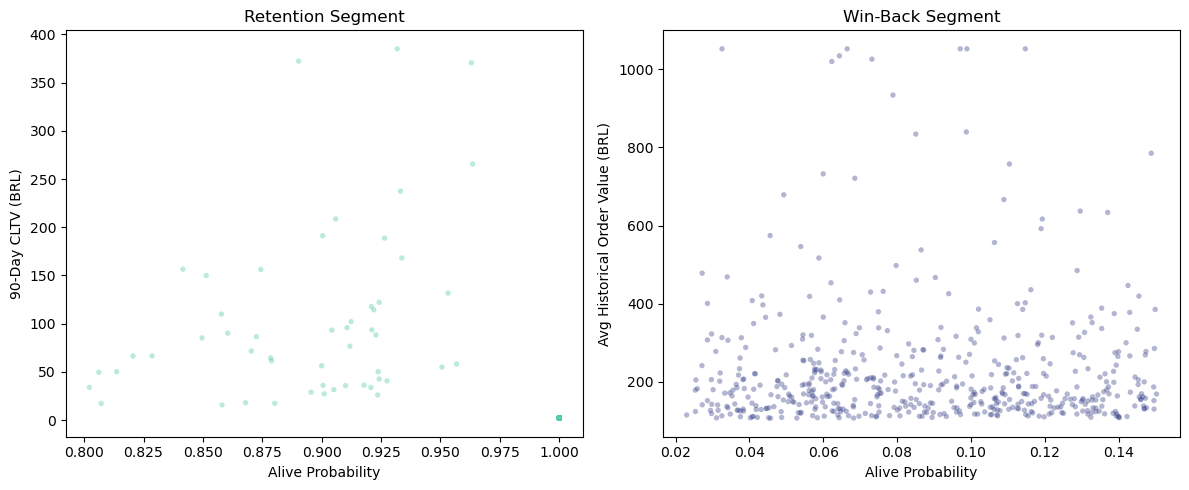

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(retention["prob_alive"], retention["cltv_90d"],
                alpha=0.4, s=15,
                color=sns.color_palette(PALETTE, 8)[6],
                edgecolors="none")
axes[0].set_xlabel("Alive Probability")
axes[0].set_ylabel("90-Day CLTV (BRL)")
axes[0].set_title("Retention Segment")

axes[1].scatter(winback["prob_alive"], winback["monetary_value"],
                alpha=0.4, s=15,
                color=sns.color_palette(PALETTE, 8)[2],
                edgecolors="none")
axes[1].set_xlabel("Alive Probability")
axes[1].set_ylabel("Avg Historical Order Value (BRL)")
axes[1].set_title("Win-Back Segment")

plt.tight_layout()
plt.savefig(FIG_DIR + "business_segments.png", dpi=DPI)
plt.show()

The retention scatter confirms that the 5,494 retained customers cluster at 
very high alive probabilities (0.80–1.00), with CLTV values ranging from near 
zero to 385 BRL. The handful of customers in the upper right — high alive 
probability combined with high predicted CLTV — represent the highest-priority 
accounts for proactive loyalty investment.

The win-back scatter shows 516 customers concentrated below 0.15 alive 
probability, with historical order values spanning 200–1,052 BRL. The absence 
of any trend between alive probability and order value confirms that high 
spenders are distributed uniformly across the churn probability range — the 
selection criterion for win-back should be monetary value, not alive 
probability alone.

---

## **Executive Summary**

### 4.1 Financial Planning — Macro View

The existing customer base of 61,872 calibration-period customers carries a 
total predicted 90-day CLTV of 80,072 BRL under the BTYD framework. This 
figure reflects only the returning segment of known customers — the dominant 
revenue driver for Olist is new customer acquisition, which accounts for 98% 
of holdout orders and lies outside the scope of both models.

For long-term budget forecasting, the BTYD approach is recommended over ML. 
The BG/NBD + Gamma-Gamma framework provides interpretable, theoretically 
grounded estimates of individual purchase probability and monetary value, 
requires no labelled holdout data to operate, and degrades gracefully as the 
prediction horizon extends. ML models offer no meaningful accuracy advantage 
on this dataset (RMSE difference < 5 BRL) while lacking the probabilistic 
interpretability that budget planning requires.

### 4.2 Operational Marketing — Micro View

Two priority segments are identified for the upcoming quarter:

**Retention (5,494 customers)** — alive probability ~1.0, combined predicted 
CLTV of 17,420 BRL. Recommended action: loyalty incentives, early access 
offers, or personalised repurchase nudges to maintain engagement.

**Win-Back (516 customers)** — alive probability 0.087, average historical 
order value 228 BRL. Recommended action: high-value reactivation campaign 
(discount voucher, personalised outreach) targeting the top 20 customers by 
monetary value first, where a single recovered purchase generates 4–7x the 
platform average revenue.